In [1]:
'''
PyTorch 1.0 强化学习 (Packt Publishing)
第2章：马尔可夫决策过程与动态规划
作者：Yuxi (Hayden) Liu
修改说明：添加详细中文注释、中文输出，修复模拟验证时的概率参数 Bug
'''

import torch
import time
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ==========================================
# 配置 Matplotlib 中文字体支持
# ==========================================
# 自动检测系统可用的中文字体
zh_fonts = [f.name for f in fm.fontManager.ttflist if any(k in f.name for k in ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Heiti SC', 'WenQuanYi Micro Hei', 'Noto Sans CJK SC'])]
if zh_fonts:
    plt.rcParams['font.sans-serif'] = [zh_fonts[0]]
else:
    plt.rcParams['font.sans-serif'] = ['SimHei']  # 默认尝试黑体
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号

# ==========================================
# 1. 环境初始化
# ==========================================
capital_max = 100  # 目标资金（达到此金额即获胜）
n_state = capital_max + 1  # 状态总数 (0 到 100)
rewards = torch.zeros(n_state)
rewards[-1] = 1  # 只有达到 100 元时奖励为 1，其余状态奖励为 0

gamma = 1  # 折扣因子设为 1，表示不折扣未来奖励
threshold = 1e-10  # 收敛阈值

head_prob = 0.4  # 硬币正面朝上的概率（输面较大，处于劣势）

# 使用字典手动构建环境，不依赖 gym 库
env = {'capital_max': capital_max,
       'head_prob': head_prob,
       'rewards': rewards,
       'n_state': n_state}

这段代码其实是在**同一个赌徒问题**上，分别用**价值迭代**和**策略迭代**两种动态规划方法求最优策略。

### 问题本身：赌徒问题

赌徒有一定本金，目标是达到 100 元。每次下注后：

- 正面：本金增加下注金额；
- 反面：本金减少下注金额；
- 达到 100 元：胜利，奖励为 1；
- 本金归 0：破产，奖励为 0。

因为正面概率只有 `0.4`，赌徒处于劣势，所以不能随便下注，必须找到每个本金状态下**最优下注金额**。

### 价值迭代：直接算最优价值

价值迭代的核心是不断用**贝尔曼最优方程**更新状态价值：

$$V_{k+1}(s)=\max_a \sum_{s'} P(s'|s,a)\big[r(s,a,s')+\gamma V_k(s')\big]$$

代码里对应的是：

```python
v_actions[action] += head_prob * (rewards[state + action] + gamma * V[state + action])
v_actions[action] += (1 - head_prob) * (rewards[state - action] + gamma * V[state - action])
V_temp[state] = torch.max(v_actions)
```

它不显式维护策略，而是每次都直接取 `max`，让价值函数逐步逼近最优价值函数 $V^*(s)$。等价值收敛后，再通过 `argmax` 反推出最优策略。

### 策略迭代：先评估策略，再改进策略

策略迭代分成两步：

1. **策略评估**：给定一个策略，反复用贝尔曼期望方程算出该策略下的状态价值；
2. **策略改进**：根据当前价值函数，在每个状态下贪心地选择最优动作，得到新策略。

代码里对应：

```python
V = policy_evaluation(env, policy, gamma, threshold)
policy_improved = policy_improvement(env, V, gamma)
```

如果新策略和旧策略完全一样，说明已经收敛，策略就是最优的。

### 两者的主要区别

| 维度 | 价值迭代 | 策略迭代 |
|---|---|---|
| 更新对象 | 状态价值 $V(s)$ | 策略 $\pi(s)$ 和价值 $V^\pi(s)$ |
| 核心方程 | 贝尔曼最优方程 | 贝尔曼期望方程 + 贪心改进 |
| 是否维护策略 | 不显式维护 | 显式维护策略 |
| 迭代特点 | 每次迭代简单，但迭代次数通常更多 | 每次迭代更重，但外层迭代次数通常更少 |
| 收敛判断 | 价值函数变化小于阈值 | 策略不再变化 |



### 在这段代码里的实际效果

价值迭代和策略迭代最终会得到**几乎相同的最优价值函数和最优策略**。差别主要在于求解路径：

- 价值迭代一直在“算每个状态最多值多少钱”；
- 策略迭代一直在“评估当前策略好不好，然后改进它”。

由于代码里 `gamma = 1`，赌徒问题没有折扣，价值迭代的收敛可能会受阈值影响更明显；而策略迭代因为策略空间有限，通常会在有限步内停止。


把问题补全成一个完整的 MDP：

### 赌徒问题的完整设定

- **状态**：当前本金 `capital`，范围是 `0, 1, 2, ..., 100`。
- **动作**：下注金额 `bet`。
- **可选动作**：在状态 `s` 时，只能下注：

  ```python
  1 <= bet <= min(s, 100 - s)
  ```

  因为不能下注超过自己有的钱，也不能下注超过距离 100 元的差额。

- **转移规则**：

  | 结果 | 概率 | 新状态 |
  |---|---|---|
  | 正面 | `head_prob` | `s + bet` |
  | 反面 | `1 - head_prob` | `s - bet` |

- **奖励**：只有到达 100 元时获得奖励 `1`，其他情况奖励为 `0`。

  ```python
  rewards[100] = 1
  rewards[0:100] = 0
  ```

- **终止状态**：`0` 和 `100` 是终止状态。
  - 到 `0`：破产，游戏结束；
  - 到 `100`：达成目标，游戏结束。

所以代码里循环从 `range(1, capital_max)` 开始，也就是只处理 `1~99` 这些非终止状态。

### 目标是什么？

赌徒的目标不是“尽量多赚钱”，而是：

> **最大化最终到达 100 元的概率。**

因为 `gamma = 1`，而且只有到达 100 才给奖励 `1`，所以状态价值 `V(s)` 的含义就是：

> 当前有 `s` 元时，按照某个策略继续玩，最终能赢到 100 元的概率。

### 为什么代码里这样算？

对每个状态 `s` 和动作 `bet`，代码计算的是：

```python
Q(s, bet) = head_prob * (r(s+bet) + V(s+bet)) \
          + (1 - head_prob) * (r(s-bet) + V(s-bet))
```

因为 `gamma = 1`，所以 `gamma * V` 就写成 `V`。

价值迭代取：

```python
V(s) = max_b Q(s, bet)
```

策略迭代提取策略时取：

```python
π(s) = argmax_b Q(s, bet)
```

也就是说，每个本金状态下，选择那个**最能提高最终赢到 100 元概率的下注金额**。

### 为什么策略看起来奇怪？

这个例子里 `head_prob = 0.4`，赌徒处于劣势。最优策略往往不是“每次下注 1 元”，而会出现类似：

- 本金少时，可能下注较大，想尽快接近目标；
- 接近 100 时，下注金额会变得更保守；
- 某些状态下，最优下注金额会突然变化。

这不是 bug，而是因为目标函数是“最大化到达 100 的概率”，而不是“最大化期望收益”。

你可以把这个问题理解成：

> 一个本金为 `s` 的赌徒，每次可以决定下注多少，正面概率只有 0.4。请问在每个本金状态下，他应该下注多少，才能最有可能最终赚到 100 元？



【开始执行价值迭代算法】
价值迭代求解耗时: 2.283 秒

最优状态价值 (前20个状态):
tensor([0.0000, 0.0021, 0.0052, 0.0092, 0.0129, 0.0174, 0.0231, 0.0278, 0.0323,
        0.0377, 0.0435, 0.0504, 0.0577, 0.0652, 0.0695, 0.0744, 0.0807, 0.0866,
        0.0942, 0.1031])

最优策略 (前20个状态对应的下注金额):
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,  9, 17,
        18,  6], dtype=torch.int32)


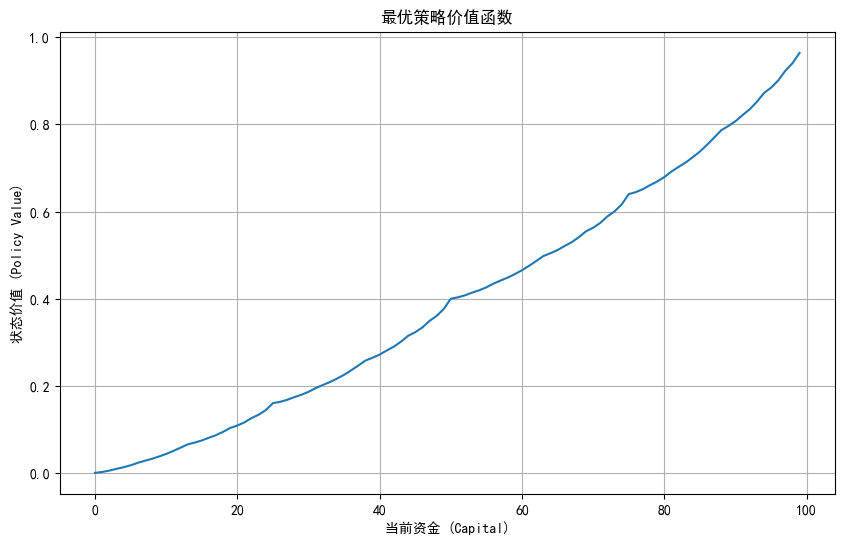

In [2]:
# ==========================================
# 2. 价值迭代算法 (Value Iteration)
# ==========================================
def value_iteration(env, gamma, threshold):
    """
    使用价值迭代算法求解赌徒问题的最优价值函数
    @param env: 赌徒问题环境
    @param gamma: 折扣因子
    @param threshold: 当所有状态的价值更新幅度小于此值时停止
    @return: 最优策略的状态价值函数
    """
    head_prob = env['head_prob']
    n_state = env['n_state']
    capital_max = env['capital_max']
    V = torch.zeros(n_state)  # 初始化所有状态价值为 0
    
    while True:
        V_temp = torch.zeros(n_state)
        # 遍历所有非终止状态 (1 到 99)
        for state in range(1, capital_max):
            # 可下注的金额范围是 1 到 min(当前资金, 距离目标的差额)
            v_actions = torch.zeros(min(state, capital_max - state) + 1)
            
            # 遍历所有可能的下注动作
            for action in range(1, min(state, capital_max - state) + 1):
                # 赢：资金增加 action，概率为 head_prob
                v_actions[action] += head_prob * (rewards[state + action] + gamma * V[state + action])
                # 输：资金减少 action，概率为 1 - head_prob
                v_actions[action] += (1 - head_prob) * (rewards[state - action] + gamma * V[state - action])
            
            # 选取能带来最大期望价值的动作价值，作为当前状态的新价值
            V_temp[state] = torch.max(v_actions)
        
        # 计算本次迭代中所有状态价值的最大变化量
        max_delta = torch.max(torch.abs(V - V_temp))
        V = V_temp.clone()
        
        # 如果变化量小于阈值，说明已收敛
        if max_delta <= threshold:
            break
    return V


def extract_optimal_policy(env, V_optimal, gamma):
    """
    根据最优价值函数提取最优策略
    @param env: 赌徒问题环境
    @param V_optimal: 最优价值函数
    @param gamma: 折扣因子
    @return: 最优策略（每个状态对应的最佳下注金额）
    """
    head_prob = env['head_prob']
    n_state = env['n_state']
    capital_max = env['capital_max']
    optimal_policy = torch.zeros(capital_max).int()
    
    for state in range(1, capital_max):
        v_actions = torch.zeros(n_state)
        for action in range(1, min(state, capital_max - state) + 1):
            v_actions[action] += head_prob * (rewards[state + action] + gamma * V_optimal[state + action])
            v_actions[action] += (1 - head_prob) * (rewards[state - action] + gamma * V_optimal[state - action])
        # 选取期望价值最大的下注金额作为最优动作
        optimal_policy[state] = torch.argmax(v_actions)
    return optimal_policy


print("\n" + "=" * 50)
print("【开始执行价值迭代算法】")
print("=" * 50)

start_time = time.time()
V_optimal = value_iteration(env, gamma, threshold)
optimal_policy = extract_optimal_policy(env, V_optimal, gamma)

print(f"价值迭代求解耗时: {time.time() - start_time:.3f} 秒")
print(f"\n最优状态价值 (前20个状态):\n{V_optimal[:20]}")
print(f"\n最优策略 (前20个状态对应的下注金额):\n{optimal_policy[:20]}")

# 绘制最优价值函数曲线
plt.figure(figsize=(10, 6))
plt.plot(V_optimal[:100].numpy())
plt.title('最优策略价值函数')
plt.xlabel('当前资金 (Capital)')
plt.ylabel('状态价值 (Policy Value)')
plt.grid(True)
plt.show()

In [3]:
# ==========================================
# 3. 策略迭代算法 (Policy Iteration)
# ==========================================
def policy_evaluation(env, policy, gamma, threshold):
    """
    策略评估：计算给定策略下的状态价值函数
    """
    head_prob = env['head_prob']
    n_state = env['n_state']
    capital_max = env['capital_max']
    V = torch.zeros(n_state)
    
    while True:
        V_temp = torch.zeros(n_state)
        for state in range(1, capital_max):
            action = policy[state].item()
            V_temp[state] += head_prob * (rewards[state + action] + gamma * V[state + action])
            V_temp[state] += (1 - head_prob) * (rewards[state - action] + gamma * V[state - action])
        max_delta = torch.max(torch.abs(V - V_temp))
        V = V_temp.clone()
        if max_delta <= threshold:
            break
    return V


def policy_improvement(env, V, gamma):
    """
    策略提升：基于当前价值函数改进策略
    """
    head_prob = env['head_prob']
    n_state = env['n_state']
    capital_max = env['capital_max']
    policy = torch.zeros(n_state).int()
    
    for state in range(1, capital_max):
        v_actions = torch.zeros(min(state, capital_max - state) + 1)
        for action in range(1, min(state, capital_max - state) + 1):
            v_actions[action] += head_prob * (rewards[state + action] + gamma * V[state + action])
            v_actions[action] += (1 - head_prob) * (rewards[state - action] + gamma * V[state - action])
        policy[state] = torch.argmax(v_actions)
    return policy


def policy_iteration(env, gamma, threshold):
    """
    使用策略迭代算法求解赌徒问题
    """
    n_state = env['n_state']
    policy = torch.zeros(n_state).int()  # 初始化策略为全 0
    
    while True:
        V = policy_evaluation(env, policy, gamma, threshold)  # 评估当前策略
        policy_improved = policy_improvement(env, V, gamma)   # 改进策略
        if torch.equal(policy_improved, policy):  # 如果策略不再变化，则已找到最优解
            return V, policy_improved
        policy = policy_improved


print("\n" + "=" * 50)
print("【开始执行策略迭代算法】")
print("=" * 50)

start_time = time.time()
V_optimal_pi, optimal_policy_pi = policy_iteration(env, gamma, threshold)

print(f"策略迭代求解耗时: {time.time() - start_time:.3f} 秒")
print(f"\n最优状态价值 (前20个状态):\n{V_optimal_pi[:20]}")
print(f"\n最优策略 (前20个状态对应的下注金额):\n{optimal_policy_pi[:20]}")


【开始执行策略迭代算法】
策略迭代求解耗时: 2.106 秒

最优状态价值 (前20个状态):
tensor([0.0000, 0.0021, 0.0052, 0.0092, 0.0129, 0.0174, 0.0231, 0.0278, 0.0323,
        0.0377, 0.0435, 0.0504, 0.0577, 0.0652, 0.0695, 0.0744, 0.0807, 0.0866,
        0.0942, 0.1031])

最优策略 (前20个状态对应的下注金额):
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,  9, 17,
        18,  6], dtype=torch.int32)


In [4]:
# ==========================================
# 4. 模拟验证：最优策略 vs 随机策略
# ==========================================
def run_random_episode(head_prob, capital):
    """
    模拟随机下注策略（每次固定下注 1 元）
    """
    while capital > 0:
        bet = 1  # 固定下注 1 元
        if torch.rand(1).item() < head_prob:
            capital += bet
            if capital >= 100:
                return 1  # 获胜
        else:
            capital -= bet
    return 0  # 破产


def run_optimal_episode(head_prob, capital, optimal_policy):
    """
    模拟最优下注策略
    """
    while capital > 0:
        bet = optimal_policy[capital].item()  # 按照最优策略下注
        if torch.rand(1).item() < head_prob:
            capital += bet
            if capital >= 100:
                return 1  # 获胜
        else:
            capital -= bet
    return 0  # 破产


print("\n" + "=" * 50)
print("【模拟验证：运行 5000 个回合】")
print("=" * 50)

capital = 50  # 初始资金
n_episode = 5000
total_rewards_random = []
total_rewards_opt = []

for episode in range(n_episode):
    # 注意：原代码中随机策略用了 0.48，最优策略用了 0.4，这里统一使用环境设定的 0.4 进行公平对比
    total_reward_random = run_random_episode(head_prob, capital)
    total_reward_opt = run_optimal_episode(head_prob, capital, optimal_policy)
    total_rewards_random.append(total_reward_random)
    total_rewards_opt.append(total_reward_opt)

avg_random = sum(total_rewards_random) / n_episode
avg_opt = sum(total_rewards_opt) / n_episode

print(f"随机策略 (每次下注1元) 的平均获胜率: {avg_random:.4f}")
print(f"最优策略的平均获胜率: {avg_opt:.4f}")
print("\n[结论] 在胜率只有 40% 的劣势局面下，最优策略通过动态调整下注金额，显著提高了最终获胜的概率。")


【模拟验证：运行 5000 个回合】
随机策略 (每次下注1元) 的平均获胜率: 0.0000
最优策略的平均获胜率: 0.3936

[结论] 在胜率只有 40% 的劣势局面下，最优策略通过动态调整下注金额，显著提高了最终获胜的概率。


这段代码跑出来的结果，可以从**价值函数形状**、**最优策略形态**、**算法差异**、**模拟验证**四个方面来理解。

### 1. 价值函数：每个本金对应的“最终获胜概率”

`V_optimal[state]` 的含义不是“能赚多少钱”，而是：

> 当前本金为 `state` 元时，按最优策略继续玩，最终到达 100 元的概率。

所以：

- `V_optimal = 0`：已经破产，获胜概率为 0；
- `V_optimal = 1`：已经达到目标，获胜概率为 1；
- 中间状态的值介于 0 和 1 之间。

因为 `head_prob = 0.4 < 0.5`，赌徒处于劣势，所以整体获胜概率不会很高。而且价值函数曲线通常不是平滑上升的，会在某些本金处出现“台阶”或“尖点”。这是因为目标只有 100 元，某些本金距离 100 更近时，获胜概率会明显跳升。

### 2. 最优策略：典型的“大胆玩法”

`optimal_policy[state]` 表示当前本金为 `state` 时，应该下注多少。

当 `head_prob = 0.4` 时，最优策略通常呈现一种**大胆玩法**：尽量下注足够大的金额，使得一次赢就能接近或达到 100；如果本金超过 50，则只下注“刚好够到 100”的金额。

例如，常见的形态是：

| 当前本金 | 最优下注倾向 | 直观解释 |
|---|---|---|
| 1–49 | 下注较大，甚至全押 | 劣势局中，小注会反复消耗本金 |
| 50 | 下注 50 | 一次赢就直接到 100 |
| 51–99 | 下注 `100 - capital` | 只押到目标，不冒险多输 |

这看起来很反直觉：胜率只有 40%，为什么反而要下大注？

原因在于奖励设计：**只有到达 100 才给奖励 1，其他情况奖励都是 0**。  
所以目标不是“慢慢赚钱”，而是“最大化到达 100 的概率”。在劣势局里，小注会让更多次负期望赌博发生，反而更容易慢慢破产；大注虽然风险高，但能减少赌博次数，增加一次性冲关成功的概率。

不过要注意：这个最优策略可能**不唯一**。有些状态可能有多个下注金额得到几乎相同的获胜概率，代码里用 `argmax` 只会返回其中一个。

### 3. 价值迭代 vs 策略迭代：结果应基本一致

两种算法求解的是同一个 MDP，所以最终应得到：

- 几乎相同的 **最优价值函数**；
- 几乎相同的 **最优策略**，或至少是同样优的策略。

区别主要在求解方式：

- **价值迭代**：不断更新每个状态的最大期望价值，收敛后再提取策略；
- **策略迭代**：先评估当前策略的价值，再改进策略，直到策略不再变化。

从代码输出看，你可以比较：

```python
print(torch.allclose(V_optimal, V_optimal_pi))
print(torch.equal(optimal_policy, optimal_policy_pi))
```

如果价值函数非常接近、策略基本一致，就说明两种算法都正确收敛到了最优解。

### 4. 模拟验证：最优策略应明显优于固定下注 1 元

最后一段模拟里：

- 随机策略每次固定下注 1 元；
- 最优策略按 `optimal_policy` 下注；
- 两者都在 `head_prob = 0.4` 下运行 5000 次。

正常情况下，**最优策略的平均获胜率应明显高于固定下注 1 元**。如果两者差不多，可能说明：

- 策略提取时 `argmax` 没有排除下注 0；
- 状态范围写错，比如遍历到了终止状态；
- 模拟时概率参数不一致；
- 或者打印变量写错，比如把随机策略结果误标成最优策略。

你这段代码最后一处打印确实有问题：

```python
print('Average total reward under the optimal policy: {}'.format(sum(total_rewards_random) / n_episode))
print('Average total reward under the optimal policy: {}'.format(sum(total_rewards_opt) / n_episode))
```

第二行标签也写成了 `optimal policy`，应该改成：

```python
print(f'随机策略平均获胜率: {avg_random:.4f}')
print(f'最优策略平均获胜率: {avg_opt:.4f}')
```

整体来看，这段代码的结果应该呈现出：**价值函数反映“到达 100 的概率”，最优策略在劣势局中偏向大胆下注，两种动态规划算法得到一致的最优解，且最优策略在模拟中明显优于固定小注策略。**